# 04 — Evaluation and Findings

This is a **reproduction of the completed July 2026 evaluation**, using the same
10,000 flights and frozen thresholds. July is already exposed; no new selection is
made. We use sklearn metrics and display tools, with **four figures**. Other evidence
uses small tables. Logistic Regression / B remains the validation-selected classifier.

In [1]:
from pathlib import Path
import sys
here = Path.cwd()
candidates = [here, *here.parents, here/'departure-delay-classification']
root = next(p for p in candidates if (p/'config/project.json').is_file())
sys.path.insert(0, str(root/'scripts'))
import simple_workflow as project

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style='whitegrid')

Matplotlib is building the font cache; this may take a moment.


In [3]:
import joblib
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, PrecisionRecallDisplay
bundle = joblib.load(project.OUT/'models.joblib')
test = pd.read_parquet(project.OUT/'features.parquet').query("role == 'july_reproduction'")
test = test.sort_values('flight_id').reset_index(drop=True)
y = test['delayed_departure'].to_numpy(dtype=int)

## O1: compare all four classifiers and simple baselines

Score the eight fitted pipelines with their frozen thresholds. Add the original
always-on-time, always-delayed, seed-42 fair-coin and historical-risk baselines.
The history baseline uses earlier airline/origin risk, origin fallback, then the
original training constant. `metric_table` uses sklearn's precision, recall, F1,
F0.5, accuracy, AP, ROC AUC and confusion-matrix functions for each comparison.

In [4]:
scores, thresholds, timings = project.score_models(bundle, test)
project.add_baselines(scores, thresholds, test)
metrics = project.metric_table(y, scores, thresholds)
display(metrics[['model_id', 'feature_set', 'f1', 'average_precision', 'precision', 'recall', 'fp', 'fn']].round(4))

,model_id,feature_set,f1,average_precision,precision,recall,fp,fn
0,logistic_regression,A,0.5012,0.5041,0.3362,0.9844,6249,50
1,logistic_regression,B,0.5395,0.5665,0.3810,0.9241,4827,244
2,knn,A,0.5132,0.4657,0.3533,0.9375,5517,201
3,knn,B,0.5454,0.5324,0.4007,0.8535,4104,471
4,svm,A,0.4866,0.4818,0.3215,1.0000,6785,0
5,svm,B,0.5342,0.5130,0.4349,0.6924,2893,989
6,random_forest,A,0.5405,0.4928,0.3975,0.8445,4116,500
7,random_forest,B,0.5429,0.5404,0.3926,0.8796,4376,387
8,always_on_time,baseline,0.0000,0.3215,NaN,0.0000,0,3215
9,always_delayed,baseline,0.4866,0.3215,0.3215,1.0000,6785,0


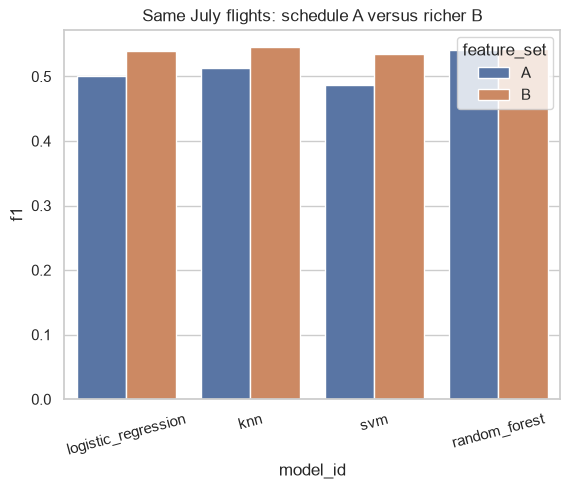

In [5]:
sns.barplot(data=metrics.query("feature_set != 'baseline'"), x='model_id', y='f1', hue='feature_set')
plt.title('Same July flights: schedule A versus richer B')
plt.xticks(rotation=15)
plt.show()

F1 balances delayed-class precision/recall; AP assesses ranking. No-skill AP equals
prevalence (.3215). Always-on-time accuracy is .6785 but its delayed F1 is zero;
always-delayed F1 is about .487. A fair coin's expected F1 here is about .391, not
universally .50. Read all metrics together. KNN's larger July F1 does not reselect it.

              precision    recall  f1-score   support

     On time      0.889     0.289     0.436      6785
     Delayed      0.381     0.924     0.540      3215

    accuracy                          0.493     10000
   macro avg      0.635     0.606     0.488     10000
weighted avg      0.726     0.493     0.469     10000



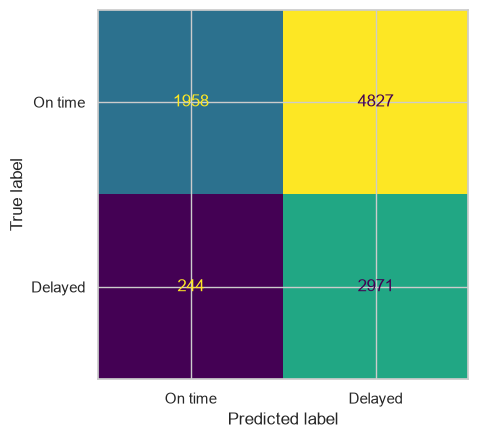

In [6]:
chosen = bundle['selected_model_id']+'__B'
prediction = scores[chosen] >= thresholds[chosen]
print(classification_report(y, prediction, target_names=['On time', 'Delayed'], digits=3))
ConfusionMatrixDisplay.from_predictions(y, prediction, display_labels=['On time', 'Delayed'], colorbar=False)
plt.show()

The selected LR/B detects 2,971 delays and misses 244, with 4,827 false warnings.
Its recall .924 comes with precision .381 and F1 .540. The curves compare B rankings
without changing the warning policy; scores remain uncalibrated (SVM uses margins).
Scoring times complement the fitting times in 03 when assessing practicality.

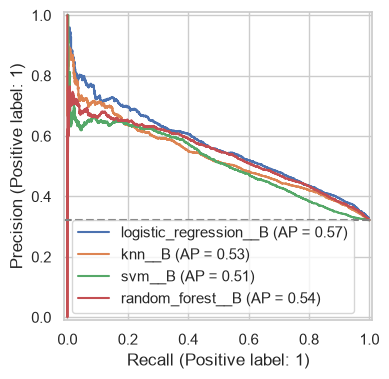

,prediction_seconds
model_inputs,
logistic_regression__A,0.022417
logistic_regression__B,0.022538
knn__A,6.631219
knn__B,11.694621
svm__A,5.538859
svm__B,13.880952
random_forest__A,0.061438
random_forest__B,0.094124


In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
for key in [k for k in scores if k.endswith('__B')]:
    PrecisionRecallDisplay.from_predictions(y, scores[key], name=key, ax=ax)
ax.axhline(y.mean(), color='grey', linestyle='--')
plt.show()
display(timings.rename_axis('model_inputs').to_frame())

## O2: does richer information help?

A/B share classifier settings, fitting IDs and time harmonics. Their thresholds use
the same October procedure separately. The saved 95% paired day-block intervals
come from the completed 300-repeat bootstrap over 31 dates, conditional on fixed fits.
This table reuses those intervals, not independent evidence. LR gains about .038 F1
and .062 AP over A; RF's F1 interval crosses zero. Individual causal contributions
of weather, history and traffic are not identified by this joint comparison.

In [8]:
gains = project.paired_gains()
display(gains[['model_id', 'f1_gain', 'f1_low', 'f1_high', 'ap_gain']].round(4))

,model_id,f1_gain,f1_low,f1_high,ap_gain
1,logistic_regression,0.0383,0.0330,0.0443,0.0623
3,knn,0.0322,0.0266,0.0369,0.0666
5,svm,0.0476,0.0362,0.0605,0.0312
7,random_forest,0.0023,-0.0033,0.0079,0.0476


## O3: where does the selected model fail?

Compute counts and supported rates by airport, airline and departure band. Precision
is TP/(TP+FP), recall TP/(TP+FN), and false-positive rate FP/(FP+TN). Small-denominator
rates stay blank under the published support rules. ORD has lower warning precision;
evening recall is high alongside nearly universal false-positive rates. These are
descriptive July patterns, not causal effects.

In [9]:
subgroups = project.error_summary(test, scores[chosen], thresholds[chosen])
columns = ['dimension', 'group_value', 'n', 'precision', 'recall', 'false_positive_rate']
display(subgroups[columns].round(3))

,dimension,group_value,n,precision,recall,false_positive_rate
0,origin,ATL,3180,0.413,0.911,0.647
1,origin,DFW,3261,0.416,0.939,0.723
2,origin,ORD,3559,0.322,0.921,0.755
3,reporting_airline,AA,2398,0.474,0.973,0.906
4,reporting_airline,AS,91,NaN,NaN,NaN
5,reporting_airline,B6,66,NaN,NaN,NaN
6,reporting_airline,DL,2701,0.393,0.896,0.621
7,reporting_airline,F9,389,0.411,1.000,0.880
8,reporting_airline,MQ,1310,0.272,0.840,0.561
9,reporting_airline,OH,214,0.401,0.863,0.667


## O4: is a smaller review list useful?

Rank the full July cohort by descending score, using the original seeded hash to
break ties. Review exactly 5%, 10% or 20%. Filtering is not used to recompute quotas.
At 10%, LR finds 688 delays among 1,000 reviewed (.688 precision, 2.14× random lift);
historical ranking finds 442. Random expected recall equals the review budget.

,ranking,budget,reviewed,captured,false_alerts,recall,precision,lift
0,logistic_regression,0.05,500,359,141,0.112,0.718,2.233
1,logistic_regression,0.10,1000,688,312,0.214,0.688,2.140
2,logistic_regression,0.20,2000,1222,778,0.380,0.611,1.900
3,historical_risk_ranking,0.05,500,221,279,0.069,0.442,1.375
4,historical_risk_ranking,0.10,1000,442,558,0.137,0.442,1.375
5,historical_risk_ranking,0.20,2000,918,1082,0.286,0.459,1.428


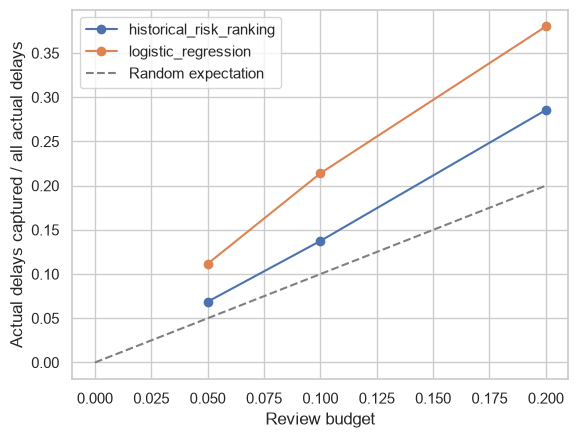

In [10]:
priority = project.priority_table(test, scores, chosen)
display(priority.round(3))
ax = priority.pivot(index='budget', columns='ranking', values='recall').plot(marker='o')
ax.plot([0, .2], [0, .2], '--', color='grey', label='Random expectation')
ax.set(xlabel='Review budget', ylabel='Actual delays captured / all actual delays')
ax.legend()
plt.show()

## Save the reproduction and interpret its limits

Ranking concentrates risk but does not establish money saved or delays prevented.
The broad warning policy still creates many false alerts. One summer month at three
origins cannot establish year-round operational reliability. Delivery/schedule
availability is assumed, and threshold transfer after refitting can alter warnings.
No July threshold was repaired.

The earlier retuned-66 comparison found LR F1 gain +.015 but negligible AP gain;
KNN improved modestly, RF's pressure package reduced AP, and SVM retained 66 inputs.
All original findings remain in the historical notebooks and published report.
The independent verification script checks every feature, principal prediction,
metric, quota, subgroup rule, dashboard summary and protected checksum.

In [11]:
project.save_evaluation(metrics, subgroups, priority, scores)

[Run and verification guide](README.md) · [Published findings](../../reports/final_models/RESULTS.md)
· [Offline dashboard](../../dashboard/dist/departure_delay_dashboard.html)
· [Project report](../../reports/final_report/README.md)